# 2×2 MMI benchmark

Benchmarks Luminescent against Tidy3D and Lumerical FDTD using the 2×2 MMI from Liu & Poon, [arXiv:2506.16665](https://arxiv.org/html/2506.16665v2), Sec. 3.3. The device is GDSFactory's generic `mmi2x2_with_sbend`: 500 nm × 220 nm Si arms tapered to 700 nm before the multimode region, with S-bends at all four ports. SiO2 cladding is above and below. Si uses a lossless Lorentzian fit to the paper's Palik model (n = 3.4729 at 1550 nm); SiO2 is constant n = 1.4425. The domain is the device plus 1 µm margins: 34 × 7 × 2.22 µm³ (the paper uses 34 × 7.5 × 4 µm³). TE0 enters o1 (lower left) at 1550 nm with a λ/12 source bandwidth (the paper uses 20 nm). The energy shutoff is 1e-4 (1e-3 for nres ≤ 10; the paper uses 1e-5). We report the cross-port (o3) transmission, the excess loss, the solve time, and the peak memory against resolution.

Paper values (Tidy3D 2.7.7 on cloud GPUs, Lumerical 2025 R1 on a 24-core CPU; transmission digitized from Fig. 12a):

| nres | Tidy3D cross T | Lumerical cross T | Tidy3D time | Lumerical time | Lumerical memory |
|---|---|---|---|---|---|
| 6 | 35.8 % | 37.6 % | 11 s | 98 s | 0.32 GB |
| 10 | 46.1 % | 45.9 % | 34 s | 259 s | 0.82 GB |
| 15 | 47.9 % | 48.3 % | 45 s | 905 s | 2.15 GB |
| 20 | 48.5 % | 48.7 % | 57 s | 2182 s | 4.48 GB |
| 25 | 48.9 % | 48.9 % | 150 s | 4813 s | 8.10 GB |

## Setup

In [1]:
import os, time, json, threading, subprocess
import numpy as np
import psutil
import matplotlib.pyplot as plt

import gdsfactory as gf
from gdsfactory.technology import LogicalLayer, LayerLevel, LayerStack
import luminescent as lumi

gf.gpdk.PDK.activate()

nres_list = [6, 10, 15]
h_wg = 0.22
wavelength = 1.55
# bandwidth = wavelength / 4
bandwidth = wavelength / 12
wavelengths = np.linspace(1.54, 1.56, 21).tolist()

# domain margins [um]
margin = 1
zmargin = 1
zmin, zmax = -zmargin, h_wg + zmargin

lumi backend: ~/Luminescent/bin/lumi


In [2]:
def setup(path, nres):
    # Si: lossless single-Lorentzian fit to the paper's Palik model (frequency in units of c / wavelength); SiO2: constant
    materials = {
        "Si": lumi.material(n=3.4729, epsilon=8.36218, dispersion=[lumi.lorentzian(3.0, 0, 3.2882)]),
        "SiO2": lumi.material(1.4425),
    }
    WG = 1, 0
    layer_stack = LayerStack(
        layers={
            "core": LayerLevel(
                layer=LogicalLayer(layer=WG),
                thickness=h_wg,
                zmin=0,
                material="Si",
                mesh_order=0,
            ),
        }
    )

    # GDSFactory generic 2x2 MMI with S-bends
    dc = gf.components.mmi2x2_with_sbend()
    xmin, ymin = dc.bbox_np()[0]
    xmax, ymax = dc.bbox_np()[1]
    bbox = [[xmin - margin, ymin - margin, zmin], [xmax + margin, ymax + margin, zmax]]

    # 10 um port extensions, cropped to the domain
    ext = gf.components.extend_ports(dc, length=10)
    dbu = ext.kcl.dbu
    arms = gf.kdb.Region(ext.begin_shapes_rec(ext.kcl.layer(*WG)))
    window = gf.kdb.Region(gf.kdb.Box(*(round(v / dbu) for v in (bbox[0][0], bbox[0][1], bbox[1][0], bbox[1][1]))))
    c = gf.Component()
    c.add_polygon(arms & window, layer=WG)
    for p in dc.ports:
        c.add_port(p.name, center=p.center, width=p.width, orientation=p.orientation, layer=WG)
    c.plot()

    frames = [
        lumi.plane_frame(
            "wg",
            start=[-1.2, zmin],
            stop=[1.2, zmax],
            wls_mode_solver=[wavelengths[0], wavelength, wavelengths[-1]],
        )
    ]
    sources = [
        lumi.gf_source("o1", c, layer_stack, margin, frame="wg", wl=wavelength, bandwidth=bandwidth)
    ]
    monitors = [lumi.gf_monitor(p, c, layer_stack, frame="wg") for p in ["o1", "o2", "o3", "o4"]]

    lumi.mesh(path, c, layer_stack, materials, zmin, zmax)
    lumi.setup(
        path=path,
        wl=wavelength,
        wls=wavelengths,
        materials=materials,
        background="SiO2",
        boundaries=["PML", "PML", "PML"],
        PML_decay=[0.001, 0.001, 0.1],
        bbox=bbox,
        frames=frames,
        sources=sources,
        monitors=monitors,
        nres=nres,
        tmax=1000,  # periods
        shutoff=1e-4,
        views=[lumi.view("Hz", z=h_wg / 2)],
        shot_every=10,
    )
    return c

## Simulate

In [3]:
def gpu_used():
    out = subprocess.run(["nvidia-smi", "--query-gpu=memory.used", "--format=csv,noheader,nounits"], capture_output=True, text=True).stdout
    return sum(float(v) for v in out.split()) / 1024  # GB


def solve_with_stats(path):
    """solve, tracking wall time, peak GPU memory (above baseline) and peak solver host RSS"""
    peak = {"gpu": 0.0, "host": 0.0}
    base = gpu_used()
    me = psutil.Process()
    done = threading.Event()

    def poll():
        while not done.is_set():
            peak["gpu"] = max(peak["gpu"], gpu_used() - base)
            rss = 0
            for p in me.children(recursive=True):
                try:
                    rss += p.memory_info().rss
                except psutil.Error:
                    pass
            peak["host"] = max(peak["host"], rss / 1024**3)
            time.sleep(0.5)

    t = threading.Thread(target=poll)
    t.start()
    t0 = time.time()
    try:
        lumi.solve(path)
    finally:
        done.set()
        t.join()
    stats = {"runtime": time.time() - t0, "gpu_GB": peak["gpu"], "host_GB": peak["host"]}
    json.dump(stats, open(os.path.join(path, "stats.json"), "w"))
    return stats

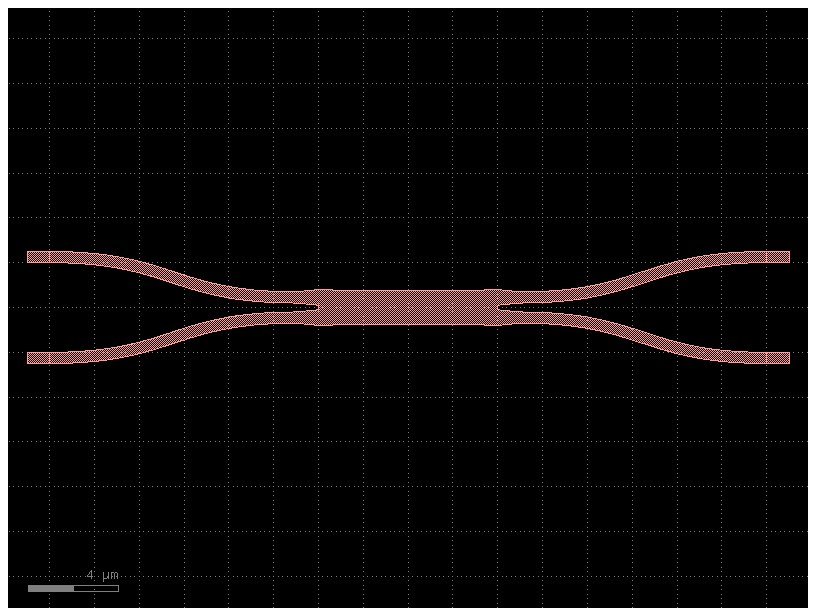

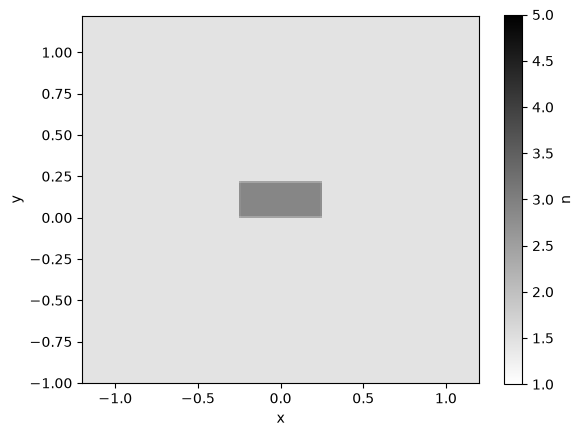

using simulation folder runs/mmi_nres6


backend using simulation folder runs/mmi_nres6


setting up simulation...


processing geometry bodies...


generating voxels...


voxelation: 10.125711 seconds (463.82 M allocations: 18.691 GiB, 25.67% gc time, 139.25% compilation time)


... (12 outputs left out)

period 160, decay: 0.004, 0.009 seconds/period, 7857.87 Mcells/s
period 170, decay: 0.004, 0.008 seconds/period, 9527.8 Mcells/s
period 180, decay: 0.003, 0.009 seconds/period, 7729.32 Mcells/s


period 190, decay: 0.002, 0.008 seconds/period, 9483.65 Mcells/s
period 198.62 stop on energy decay
8489.5 Mcells/s


simulation completed.


{'runtime': 126.59987044334412, 'gpu_GB': 1.2353515625, 'host_GB': 2.4572982788085938}


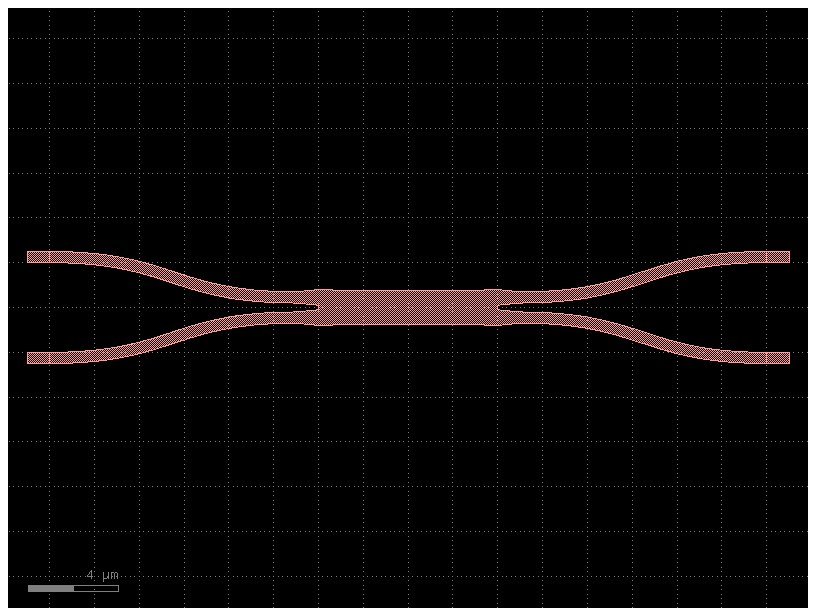

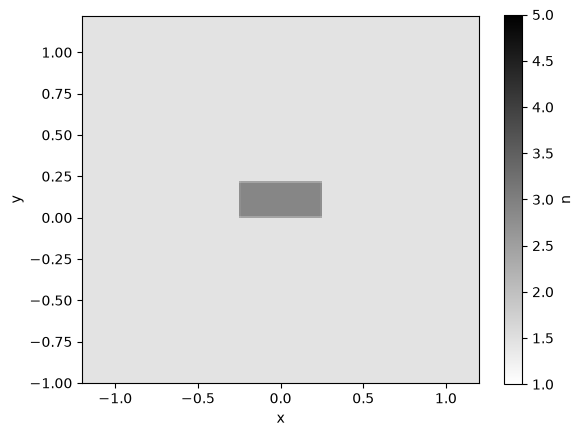

using simulation folder runs/mmi_nres10


backend using simulation folder runs/mmi_nres10


setting up simulation...


processing geometry bodies...


generating voxels...


voxelation: 26.456843 seconds (1.34 G allocations: 51.541 GiB, 33.84% gc time, 54.07% compilation time)


... (25 outputs left out)

period 180, decay: 0.002, 0.057 seconds/period, 9293.57 Mcells/s


period 185.47 stop on energy decay
9241.58 Mcells/s


simulation completed.


{'runtime': 154.33912324905396, 'gpu_GB': 3.0791015625, 'host_GB': 3.585926055908203}


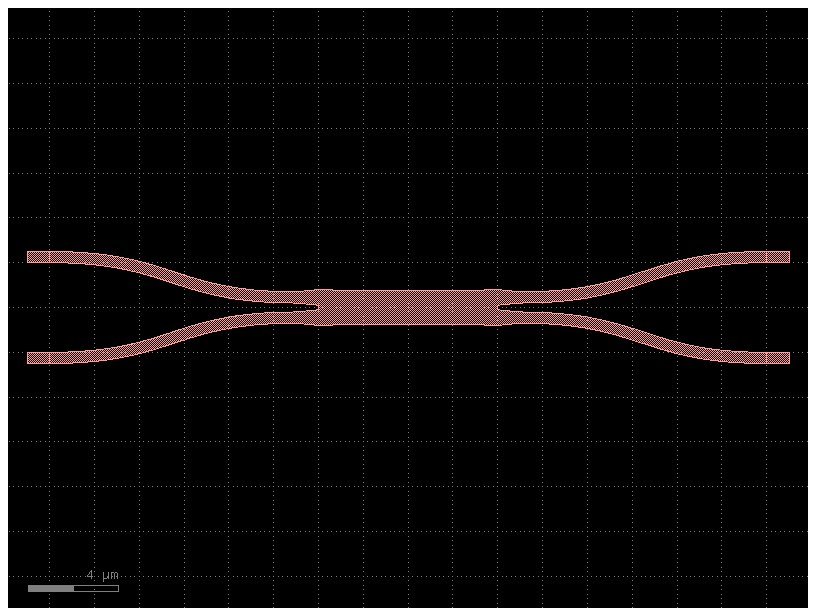

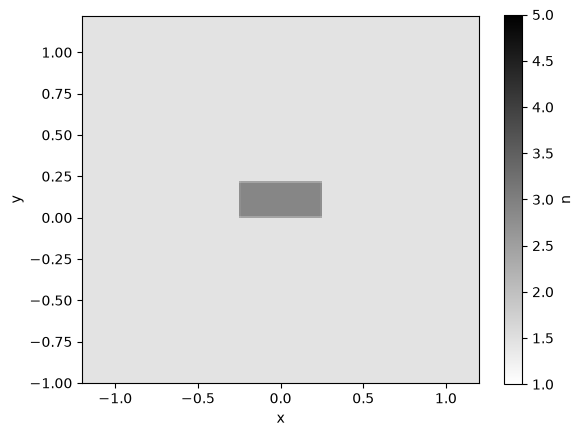

using simulation folder runs/mmi_nres15


backend using simulation folder runs/mmi_nres15


setting up simulation...


processing geometry bodies...


generating voxels...


voxelation: 41.084999 seconds (3.27 G allocations: 122.792 GiB, 31.09% gc time, 45.66% compilation time)


... (21 outputs left out)

period 140, decay: 0.0, 0.304 seconds/period, 7929.28 Mcells/s


period 144 stop on energy decay
7826.55 Mcells/s


simulation completed.


{'runtime': 205.23535656929016, 'gpu_GB': 9.7978515625, 'host_GB': 4.730339050292969}


In [4]:
for nres in nres_list:
    path = os.path.join("runs", f"mmi_nres{nres}")
    setup(path, nres)
    print(solve_with_stats(path))

## Results

loading solution from runs/mmi_nres6
may take a minute if simulation folder is remotely mounted
loading solution from runs/mmi_nres10
may take a minute if simulation folder is remotely mounted
loading solution from runs/mmi_nres15
may take a minute if simulation folder is remotely mounted
nres  cross T  through T  excess loss  runtime  GPU mem  host mem
   6    35.3 %     47.0 %     0.843 dB    127 s   1.24 GB   2.46 GB
  10    45.7 %     49.2 %     0.227 dB    154 s   3.08 GB   3.59 GB
  15    47.6 %     48.4 %     0.177 dB    205 s   9.80 GB   4.73 GB


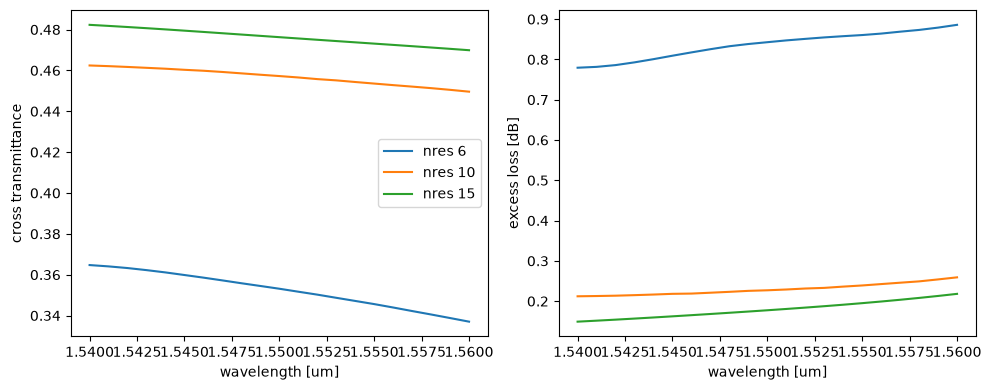

In [5]:
wls = np.array(wavelengths)
i = np.argmin(abs(wls - wavelength))
rows = []
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for nres in [6, 10, 15]:
    path = os.path.join("runs", f"mmi_nres{nres}")
    if not os.path.exists(os.path.join(path, "solution.json")):
        continue
    m = lumi.load(path)["monitors"]
    a1 = m["o1"]["modes"][0]["-"]
    T3 = np.abs(m["o3"]["modes"][0]["+"] / a1) ** 2  # cross
    T4 = np.abs(m["o4"]["modes"][0]["+"] / a1) ** 2  # through
    loss = -10 * np.log10(T3 + T4)
    f = os.path.join(path, "stats.json")
    st = json.load(open(f)) if os.path.exists(f) else {}
    rows.append((nres, T3[i], T4[i], loss[i], st.get("runtime"), st.get("gpu_GB"), st.get("host_GB")))
    ax[0].plot(wls, T3, label=f"nres {nres}")
    ax[1].plot(wls, loss, label=f"nres {nres}")

fmt = lambda v, f: "–" if v is None else format(v, f)
print("nres  cross T  through T  excess loss  runtime  GPU mem  host mem")
for nres, t3, t4, l, rt, g, h in rows:
    print(f"{nres:4d}  {100*t3:6.1f} %  {100*t4:7.1f} %  {l:8.3f} dB  {fmt(rt, '5.0f'):>5} s  {fmt(g, '5.2f'):>5} GB  {fmt(h, '5.2f'):>5} GB")

ax[0].set(xlabel="wavelength [um]", ylabel="cross transmittance")
ax[1].set(xlabel="wavelength [um]", ylabel="excess loss [dB]")
ax[0].legend()
plt.tight_layout()
plt.show()

## Fig. 12a comparison

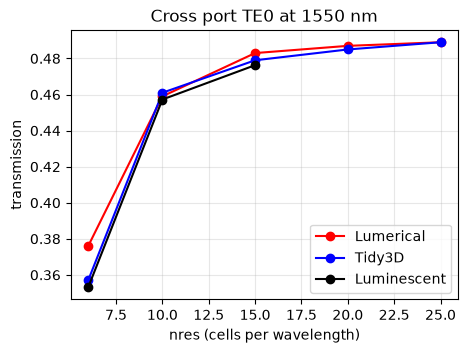

In [6]:
# paper Fig. 12a, digitized
nres_paper = [6, 10, 15, 20, 25]
T_tidy3d = [0.357, 0.461, 0.479, 0.485, 0.489]
T_lumerical = [0.376, 0.459, 0.483, 0.487, 0.489]

plt.figure(figsize=(5, 3.5))
plt.plot(nres_paper, T_lumerical, "o-", color="red", label="Lumerical")
plt.plot(nres_paper, T_tidy3d, "o-", color="blue", label="Tidy3D")
plt.plot([r[0] for r in rows], [r[1] for r in rows], "o-", color="black", label="Luminescent")
plt.xlabel("nres (cells per wavelength)")
plt.ylabel("transmission")
plt.title("Cross port TE0 at 1550 nm")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## Movie

In [7]:
nres_list = [6]